# 01 - Data exploration

**Dataset:** CDC Diabetes Health Indicators (BRFSS 2015), from the UCI Machine Learning Repository.

**Goal of this notebook:** understand the raw data before loading it into SQL -
its size, quality, class balance and which factors are linked to diabetes.

Run `python src/download_data.py` first to fetch the CSV. Column meanings are in `docs/data_dictionary.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GRID, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "ytick.left": False, "text.color": INK, "font.size": 10,
})

df = pd.read_csv(Path("..") / "data" / "raw" / "cdc_diabetes_health_indicators.csv")
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

253,680 rows x 23 columns


,ID,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,1,40,1,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,1,0,0,0,0,25,1,0,0,1,...,0,1,3,0,0,0,0,7,6,1
2,2,0,1,1,1,28,0,0,0,0,...,1,1,5,30,30,1,0,9,4,8
3,3,0,1,0,1,27,0,0,0,1,...,1,0,2,0,0,0,0,11,3,6
4,4,0,1,1,1,24,0,0,0,1,...,1,0,2,3,0,0,0,11,5,4


## 1. Data quality

In [2]:
features = df.drop(columns="ID")

print("Missing values:     ", int(df.isna().sum().sum()))
print("Column types:       ", df.dtypes.astype(str).value_counts().to_dict())
print("ID is unique:       ", df["ID"].is_unique)
print("Identical responses:", f"{features.duplicated().sum():,} rows share all 22 answers with an earlier row")

features.agg(["min", "max", "nunique"]).T

Missing values:      0
Column types:        {'int64': 23}
ID is unique:        True
Identical responses: 24,206 rows share all 22 answers with an earlier row


,min,max,nunique
Diabetes_binary,0,1,2
HighBP,0,1,2
HighChol,0,1,2
CholCheck,0,1,2
BMI,12,98,84
Smoker,0,1,2
Stroke,0,1,2
HeartDiseaseorAttack,0,1,2
PhysActivity,0,1,2
Fruits,0,1,2


**Findings**

- No missing values and every column is an integer, so the load into SQL needs no cleaning.
- About 24,000 rows have exactly the same answers as another row. With 21 mostly yes/no questions and a
  quarter of a million respondents this is expected, not an error - each has its own `ID`, so they are kept.
- 14 features are binary, `GenHlth`, `Age`, `Education` and `Income` are ordered codes, and only `BMI`,
  `MentHlth` and `PhysHlth` behave like numbers.

## 2. Class balance

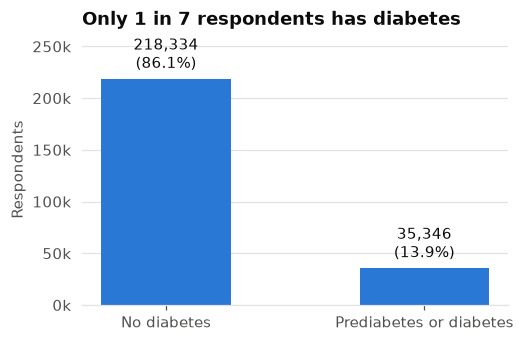

In [3]:
counts = df["Diabetes_binary"].value_counts().sort_index()
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(["No diabetes", "Prediabetes or diabetes"], counts.values, color=BLUE, width=0.5)
ax.bar_label(bars, labels=[f"{c:,}\n({s:.1f}%)" for c, s in zip(counts, share)], padding=4)
ax.set_title("Only 1 in 7 respondents has diabetes")
ax.set_ylabel("Respondents")
ax.set_ylim(0, counts.max() * 1.2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
plt.show()

**Finding:** the classes are imbalanced (13.9% positive). A model that always says "no diabetes" would be
86% accurate, so accuracy is the wrong metric. Step 6 will use ROC-AUC, precision-recall and calibration instead.

## 3. BMI

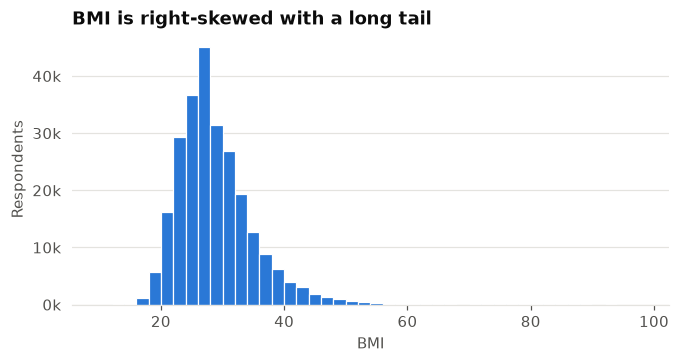

count    253680.0
mean         28.4
std           6.6
min          12.0
25%          24.0
50%          27.0
75%          31.0
max          98.0

BMI above 60: 805 rows   BMI below 15: 68 rows


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(df["BMI"], bins=range(10, 100, 2), color=BLUE, edgecolor="white", linewidth=0.8)
ax.set_title("BMI is right-skewed with a long tail")
ax.set_xlabel("BMI")
ax.set_ylabel("Respondents")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
plt.show()

print(df["BMI"].describe().round(1).to_string())
print(f"\nBMI above 60: {(df['BMI'] > 60).sum():,} rows   BMI below 15: {(df['BMI'] < 15).sum():,} rows")

**Finding:** the median BMI is 27 (overweight). Under 1,000 rows have extreme values (above 60 or below 15).
These are plausible but rare, so they are kept, and the SQL layer will group BMI into the standard WHO categories.

## 4. Diabetes rate by age

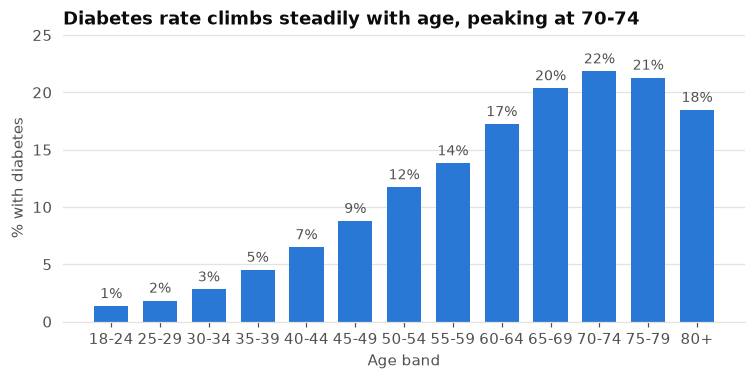

In [5]:
AGE_LABELS = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]

by_age = df.groupby("Age")["Diabetes_binary"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(AGE_LABELS, by_age.values, color=BLUE, width=0.7)
ax.bar_label(bars, fmt="%.0f%%", padding=3, color=MUTED, fontsize=9)
ax.set_title("Diabetes rate climbs steadily with age, peaking at 70-74")
ax.set_xlabel("Age band")
ax.set_ylabel("% with diabetes")
ax.set_ylim(0, by_age.max() * 1.15)
plt.show()

## 5. Diabetes rate for each yes/no factor

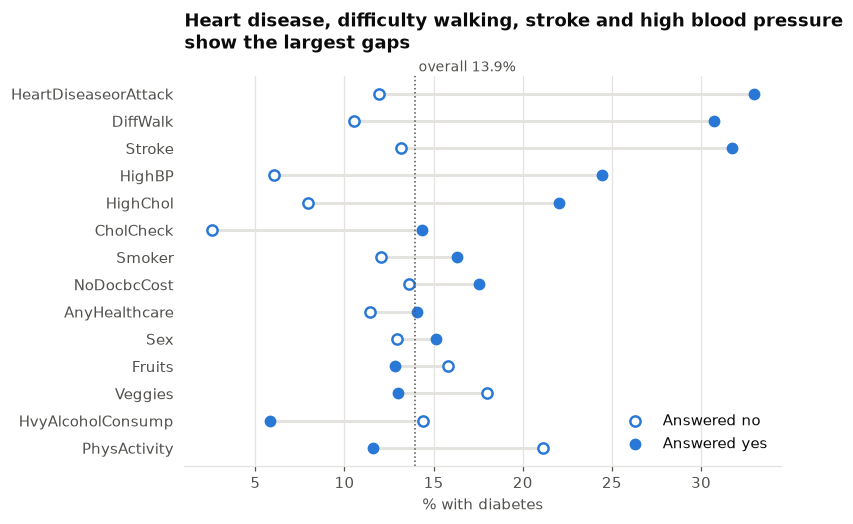

,No,Yes,Difference
HeartDiseaseorAttack,12.0,33.0,21.0
DiffWalk,10.5,30.7,20.2
Stroke,13.2,31.8,18.6
HighBP,6.0,24.4,18.4
HighChol,8.0,22.0,14.0
CholCheck,2.5,14.4,11.8
Smoker,12.1,16.3,4.2
NoDocbcCost,13.6,17.5,3.9
AnyHealthcare,11.5,14.1,2.6
Sex,13.0,15.2,2.2


In [6]:
binary_cols = [c for c in features.columns if features[c].nunique() == 2 and c != "Diabetes_binary"]

rates = pd.DataFrame({
    "No": [df.loc[df[c] == 0, "Diabetes_binary"].mean() * 100 for c in binary_cols],
    "Yes": [df.loc[df[c] == 1, "Diabetes_binary"].mean() * 100 for c in binary_cols],
}, index=binary_cols)
rates["Difference"] = rates["Yes"] - rates["No"]
rates = rates.sort_values("Difference")

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.hlines(rates.index, rates["No"], rates["Yes"], color=GRID, linewidth=2, zorder=1)
ax.scatter(rates["No"], rates.index, s=45, color="white", edgecolor=BLUE, linewidth=1.6, zorder=2, label="Answered no")
ax.scatter(rates["Yes"], rates.index, s=45, color=BLUE, zorder=2, label="Answered yes")
ax.axvline(df["Diabetes_binary"].mean() * 100, color=MUTED, linewidth=1, linestyle=":")
ax.text(df["Diabetes_binary"].mean() * 100, len(rates) - 0.3, " overall 13.9%", color=MUTED, fontsize=9, va="bottom")
ax.set_title("Heart disease, difficulty walking, stroke and high blood pressure\nshow the largest gaps", pad=18)
ax.set_xlabel("% with diabetes")
ax.legend(frameon=False, loc="lower right")
plt.show()

rates.round(1).sort_values("Difference", ascending=False)

Note that `Sex` is coded 0 = female, 1 = male, so "yes" on that row means male.

`HvyAlcoholConsump` shows a *lower* diabetes rate for heavy drinkers. This is a known quirk of this survey and
is almost certainly not causal (people who are diagnosed are often told to stop drinking). It is a good example
of why this model can describe associations but not causes.

## 6. Correlation with the target

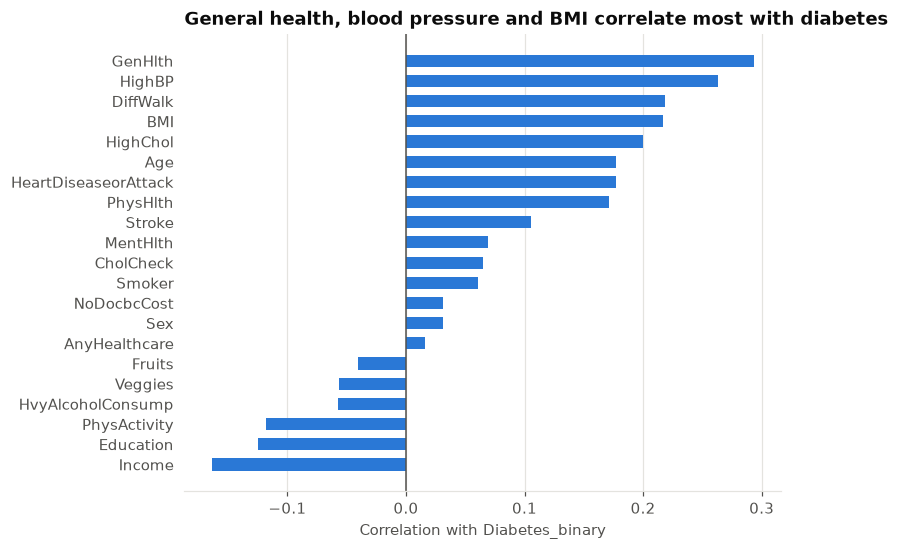

In [7]:
corr = features.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()

fig, ax = plt.subplots(figsize=(7, 5.4))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.barh(corr.index, corr.values, color=BLUE, height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_title("General health, blood pressure and BMI correlate most with diabetes")
ax.set_xlabel("Correlation with Diabetes_binary")
plt.show()

## Summary

| Question | Answer |
|---|---|
| Size | 253,680 rows, 21 features plus an ID and the target |
| Missing data | None |
| Class balance | 13.9% positive - imbalanced |
| Strongest signals | General health, high blood pressure, difficulty walking, BMI, high cholesterol, age |
| Weak signals | Fruit, vegetables, sex, healthcare coverage |

**What this means for the next steps**

- **Step 3 (schema):** the columns split naturally into demographics, lifestyle and clinical measures.
- **Step 4 (SQL features):** BMI categories, wider age groups and a count of risk factors are worth building as views.
- **Step 6 (model):** no single feature is strongly correlated (the highest is 0.29), so the model has to combine
  many weak signals, and it must be judged on ROC-AUC and calibration rather than accuracy.

**Limitations to state in the README**

- Everything is self-reported by phone, from 2015, for US adults only.
- The target combines prediabetes and diabetes, and does not separate type 1 from type 2.
- The data shows associations, not causes.